# **Marketing_Campaign_Analysis**

In [1]:
import pandas as pd
import urllib.request
import zipfile
from pathlib import Path

# Download the dataset
url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
zip_path = "/content/bank_marketing.zip"

print("Downloading dataset...")

urllib.request.urlretrieve(url, zip_path)

# Extract the ZIP file
extract_path = Path("/content/bank_data")
extract_path.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Download completed!")

# Find the CSV file automatically
csv_files = list(extract_path.rglob("bank-additional-full.csv"))

if csv_files:
    csv_path = csv_files[0]

    # Load the dataset
    df = pd.read_csv(csv_path, sep=";")

    print("\nDataset loaded successfully!")
    print("Number of rows and columns:", df.shape)

    display(df.head())

else:
    print("CSV file not found.")
    print("Files extracted:")

    for file in extract_path.rglob("*"):
        if file.is_file():
            print(file)

Download completed!
CSV file not found.
Files extracted:
/content/bank_data/bank.zip
/content/bank_data/bank-additional.zip


In [2]:
import zipfile
from pathlib import Path

# Find the bank-additional.zip file
zip_path = "/content/bank_data/bank-additional.zip"

# Extract its contents
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content/bank_data/additional_data")

print("Dataset extracted successfully!")

# Find the CSV file
for file in Path("/content/bank_data/additional_data").rglob("*.csv"):
    print(file)

Dataset extracted successfully!
/content/bank_data/additional_data/bank-additional/bank-additional.csv
/content/bank_data/additional_data/bank-additional/bank-additional-full.csv


In [3]:
import pandas as pd

# Load the dataset
df = pd.read_csv(
    "/content/bank_data/additional_data/bank-additional/bank-additional-full.csv",
    sep=";"
)

# Display the results
print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

# Display the first five rows
df.head()

Dataset loaded successfully!
Number of rows and columns: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Check all column names
print("\nColumn names:")
print(df.columns.tolist())

# Check the data types
print("\nData types:")
print(df.dtypes)

Dataset shape: (41188, 21)

Column names:
['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']

Data types:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object


In [5]:
print(df.isnull().sum())

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [6]:
print("Total number of missing value:" , df.isnull().sum())

Total number of missing value: age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64


In [7]:
print("Number of duplicated values: ", df.duplicated().sum())

Number of duplicated values:  12


In [8]:
print(df.duplicated())

0        False
1        False
2        False
3        False
4        False
         ...  
41183    False
41184    False
41185    False
41186    False
41187    False
Length: 41188, dtype: bool


In [9]:
# Remove duplicate rows
df = df.drop_duplicates()

# Check the dataset after removing duplicates
print("Dataset shape after removing duplicates:", df.shape)

# Check duplicates again
print("Remaining duplicate rows:", df.duplicated().sum())

Dataset shape after removing duplicates: (41176, 21)
Remaining duplicate rows: 0


In [10]:
# Count customers who subscribed and did not subscribe
print(df['y'].value_counts())

y
no     36537
yes     4639
Name: count, dtype: int64


In [11]:
# Calculate subscription percentages
subscription_percentage = df['y'].value_counts(normalize=True) * 100

print(subscription_percentage.round(2))


y
no     88.73
yes    11.27
Name: proportion, dtype: float64


In [12]:
# Check basic statistics for customer age
print(df['age'].describe())

count    41176.00000
mean        40.02380
std         10.42068
min         17.00000
25%         32.00000
50%         38.00000
75%         47.00000
max         98.00000
Name: age, dtype: float64


In [13]:
# Count customers in each job category
print(df['job'].value_counts())

job
admin.           10419
blue-collar       9253
technician        6739
services          3967
management        2924
retired           1718
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64


In [14]:
# Count customers by education level
print(df['education'].value_counts())

education
university.degree      12164
high.school             9512
basic.9y                6045
professional.course     5240
basic.4y                4176
basic.6y                2291
unknown                 1730
illiterate                18
Name: count, dtype: int64


In [15]:
# Count customers by marital status
print(df['marital'].value_counts())

marital
married     24921
single      11564
divorced     4611
unknown        80
Name: count, dtype: int64


In [16]:
# Count customers by contact method
print(df['contact'].value_counts())

contact
cellular     26135
telephone    15041
Name: count, dtype: int64


In [17]:
# Compare contact method with subscription result
print(pd.crosstab(df['contact'], df['y']))

y             no   yes
contact               
cellular   22283  3852
telephone  14254   787


In [18]:
# Compare job category with subscription result
print(pd.crosstab(df['job'], df['y']))

y                no   yes
job                      
admin.         9068  1351
blue-collar    8615   638
entrepreneur   1332   124
housemaid       954   106
management     2596   328
retired        1284   434
self-employed  1272   149
services       3644   323
student         600   275
technician     6009   730
unemployed      870   144
unknown         293    37


In [19]:
# Calculate subscription rate for each job category
job_subscription_rate = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

# Show only the percentage of customers who subscribed
print(job_subscription_rate['yes'].sort_values(ascending=False).round(2))

job
student          31.43
retired          25.26
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.90
Name: yes, dtype: float64


In [20]:
# Calculate subscription rate for each job category
job_subscription_rate = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

# Show only the percentage of customers who subscribed
print(job_subscription_rate['yes'].sort_values(ascending=False).round(2))

job
student          31.43
retired          25.26
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.90
Name: yes, dtype: float64


In [21]:
# Calculate subscription rate for each job category
job_subscription_rate = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

# Show only the percentage of customers who subscribed
print(job_subscription_rate['yes'].sort_values(ascending=False).round(2))

job
student          31.43
retired          25.26
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.90
Name: yes, dtype: float64


In [22]:
# Compare education level with subscription result
print(pd.crosstab(df['education'], df['y']))

y                       no   yes
education                       
basic.4y              3748   428
basic.6y              2103   188
basic.9y              5572   473
high.school           8481  1031
illiterate              14     4
professional.course   4645   595
university.degree    10495  1669
unknown               1479   251


In [23]:
# Calculate subscription rate by education level
education_rate = pd.crosstab(
    df['education'],
    df['y'],
    normalize='index'
) * 100

# Display subscription rates from highest to lowest
print(education_rate['yes'].sort_values(ascending=False).round(2))

education
illiterate             22.22
unknown                14.51
university.degree      13.72
professional.course    11.35
high.school            10.84
basic.4y               10.25
basic.6y                8.21
basic.9y                7.82
Name: yes, dtype: float64


In [24]:
# Compare marital status with subscription result
print(pd.crosstab(df['marital'], df['y']))

y            no   yes
marital              
divorced   4135   476
married   22390  2531
single     9944  1620
unknown      68    12


In [25]:
# Calculate subscription rate by marital status
marital_rate = pd.crosstab(
    df['marital'],
    df['y'],
    normalize='index'
) * 100

# Display subscription rates from highest to lowest
print(marital_rate['yes'].sort_values(ascending=False).round(2))

marital
unknown     15.00
single      14.01
divorced    10.32
married     10.16
Name: yes, dtype: float64


In [26]:
# Compare month with subscription result
print(pd.crosstab(df['month'], df['y']))

y         no  yes
month            
apr     2092  539
aug     5521  655
dec       93   89
jul     6521  648
jun     4759  559
mar      270  276
may    12881  886
nov     3684  416
oct      402  315
sep      314  256


In [27]:
# Calculate subscription rate by month
month_rate = pd.crosstab(
    df['month'],
    df['y'],
    normalize='index'
) * 100

# Display subscription rates from highest to lowest
print(month_rate['yes'].sort_values(ascending=False).round(2))

month
mar    50.55
dec    48.90
sep    44.91
oct    43.93
apr    20.49
aug    10.61
jun    10.51
nov    10.15
jul     9.04
may     6.44
Name: yes, dtype: float64


In [28]:
# Compare number of campaign contacts with subscription result
print(pd.crosstab(df['campaign'], df['y']))

y            no   yes
campaign             
1         15335  2299
2          9357  1211
3          4766   574
4          2401   249
5          1479   120
6           904    75
7           591    38
8           383    17
9           266    17
10          213    12
11          165    12
12          122     3
13           88     4
14           68     1
15           49     2
16           51     0
17           54     4
18           33     0
19           26     0
20           30     0
21           24     0
22           17     0
23           15     1
24           15     0
25            8     0
26            8     0
27           11     0
28            8     0
29           10     0
30            7     0
31            7     0
32            4     0
33            4     0
34            3     0
35            5     0
37            1     0
39            1     0
40            2     0
41            1     0
42            2     0
43            2     0
56            1     0


In [29]:
# Calculate subscription rate by number of campaign contacts
campaign_rate = pd.crosstab(
    df['campaign'],
    df['y'],
    normalize='index'
) * 100

# Display the subscription rate for the first 10 contact counts
print(campaign_rate[['yes']].head(10).round(2))

y           yes
campaign       
1         13.04
2         11.46
3         10.75
4          9.40
5          7.50
6          7.66
7          6.04
8          4.25
9          6.01
10         5.33


In [30]:
# Calculate subscription rate by contact method
contact_rate = pd.crosstab(
    df['contact'],
    df['y'],
    normalize='index'
) * 100

print(contact_rate['yes'].round(2))

contact
cellular     14.74
telephone     5.23
Name: yes, dtype: float64


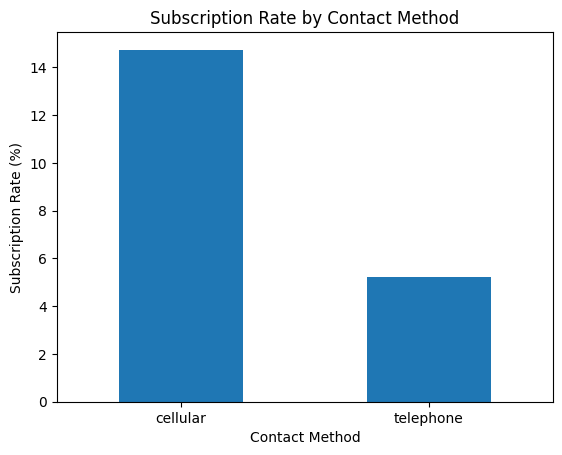

In [31]:
import matplotlib.pyplot as plt

# Calculate subscription rate by contact method
contact_rate = pd.crosstab(
    df['contact'],
    df['y'],
    normalize='index'
) * 100

# Create bar chart
contact_rate['yes'].plot(kind='bar')

plt.title('Subscription Rate by Contact Method')
plt.xlabel('Contact Method')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.show()

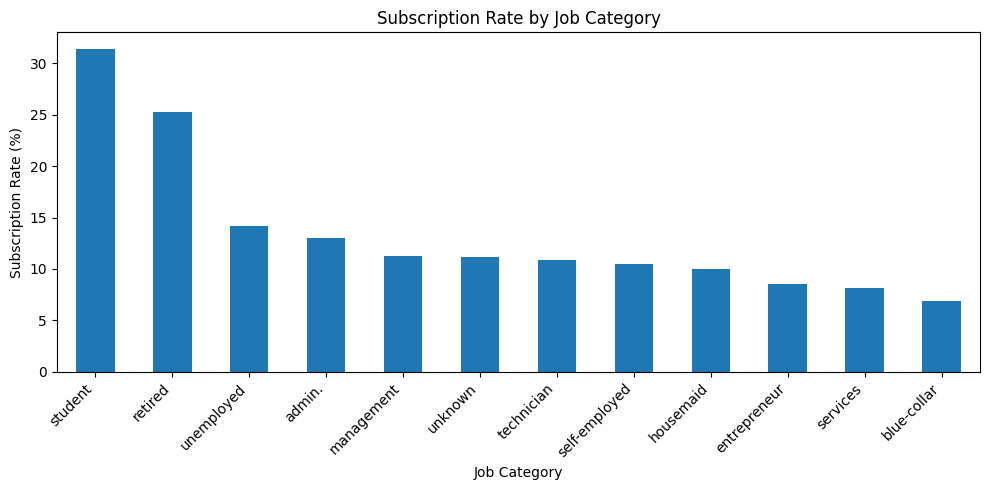

In [32]:
import matplotlib.pyplot as plt

# Calculate subscription rate by job category
job_rate = pd.crosstab(
    df['job'],
    df['y'],
    normalize='index'
) * 100

# Sort job categories by subscription rate
job_rate = job_rate.sort_values(by='yes', ascending=False)

# Create bar chart
job_rate['yes'].plot(kind='bar', figsize=(10, 5))

plt.title('Subscription Rate by Job Category')
plt.xlabel('Job Category')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

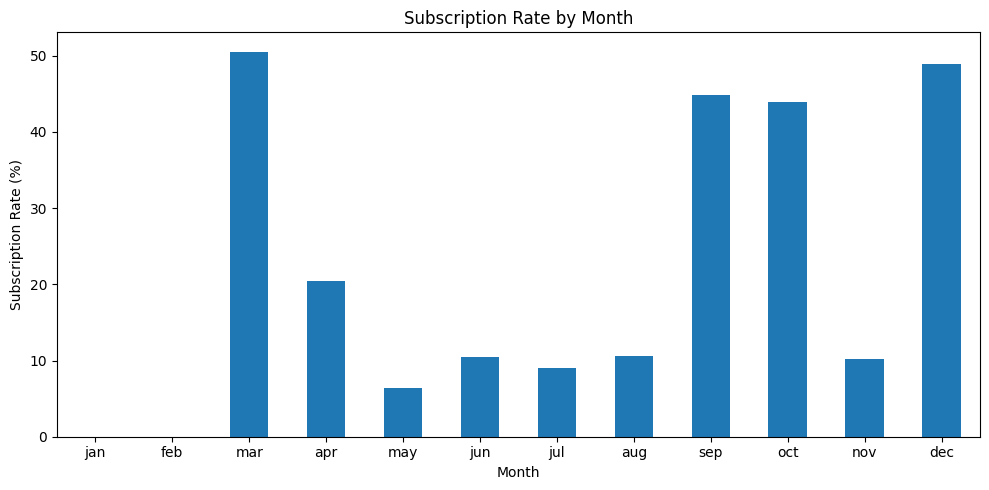

In [33]:
import matplotlib.pyplot as plt

# Calculate subscription rate by month
month_rate = pd.crosstab(
    df['month'],
    df['y'],
    normalize='index'
) * 100

# Arrange months in calendar order
month_order = [
    'jan', 'feb', 'mar', 'apr', 'may', 'jun',
    'jul', 'aug', 'sep', 'oct', 'nov', 'dec'
]

month_rate = month_rate.reindex(month_order)

# Create bar chart
month_rate['yes'].plot(kind='bar', figsize=(10, 5))

plt.title('Subscription Rate by Month')
plt.xlabel('Month')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

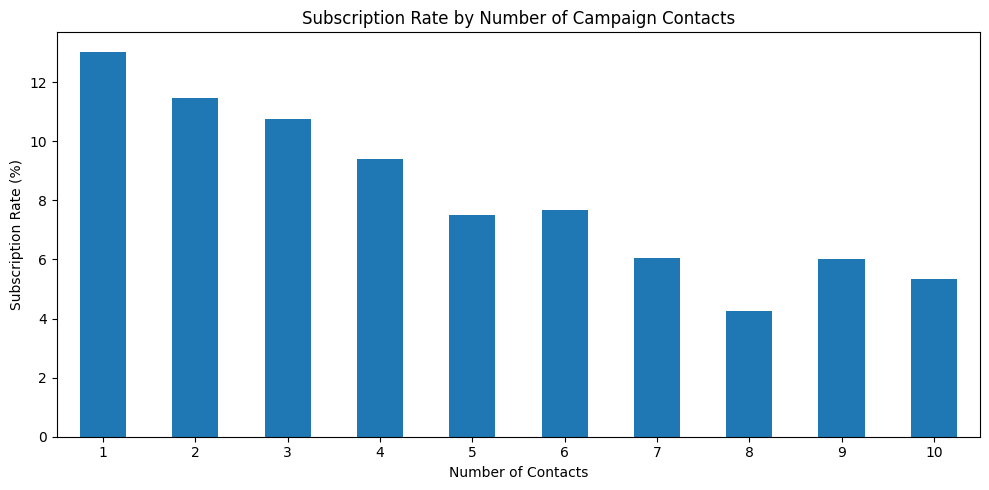

In [34]:
import matplotlib.pyplot as plt

# Calculate subscription rate by campaign contacts
campaign_rate = pd.crosstab(
    df['campaign'],
    df['y'],
    normalize='index'
) * 100

# Select contact counts from 1 to 10
campaign_rate = campaign_rate.loc[1:10]

# Create bar chart
campaign_rate['yes'].plot(kind='bar', figsize=(10, 5))

plt.title('Subscription Rate by Number of Campaign Contacts')
plt.xlabel('Number of Contacts')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [35]:
# Create age groups
df['age_group'] = pd.cut(
    df['age'],
    bins=[17, 25, 35, 45, 55, 65, 100],
    labels=[
        '18-25',
        '26-35',
        '36-45',
        '46-55',
        '56-65',
        '66+'
    ],
    include_lowest=True
)

# Compare age groups with subscription result
print(pd.crosstab(df['age_group'], df['y']))

y             no   yes
age_group             
18-25       1316   349
26-35      13104  1740
36-45      11747  1092
46-55       7530   717
56-65       2512   451
66+          328   290


In [36]:
# Calculate subscription rate by age group
age_rate = pd.crosstab(
    df['age_group'],
    df['y'],
    normalize='index'
) * 100

# Display subscription rates from highest to lowest
print(age_rate['yes'].sort_values(ascending=False).round(2))

age_group
66+      46.93
18-25    20.96
56-65    15.22
26-35    11.72
46-55     8.69
36-45     8.51
Name: yes, dtype: float64


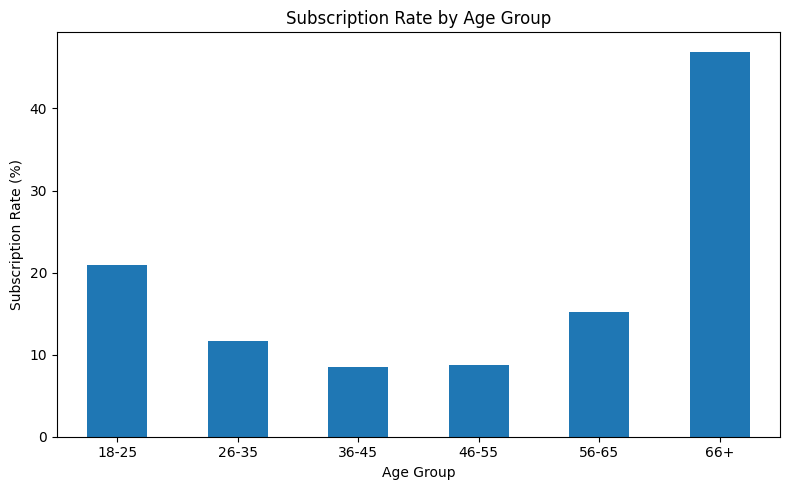

In [37]:
import matplotlib.pyplot as plt

# Calculate subscription rate by age group
age_rate = pd.crosstab(
    df['age_group'],
    df['y'],
    normalize='index'
) * 100

# Create the bar chart
age_rate['yes'].plot(kind='bar', figsize=(8, 5))

plt.title('Subscription Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [38]:
# Count subscriptions by previous campaign outcome
print(pd.crosstab(df['poutcome'], df['y']))

y               no   yes
poutcome                
failure       3647   605
nonexistent  32411  3140
success        479   894


In [39]:
# Calculate subscription rate by previous campaign outcome
poutcome_rate = pd.crosstab(
    df['poutcome'],
    df['y'],
    normalize='index'
) * 100

print(poutcome_rate['yes'].sort_values(ascending=False).round(2))

poutcome
success        65.11
failure        14.23
nonexistent     8.83
Name: yes, dtype: float64


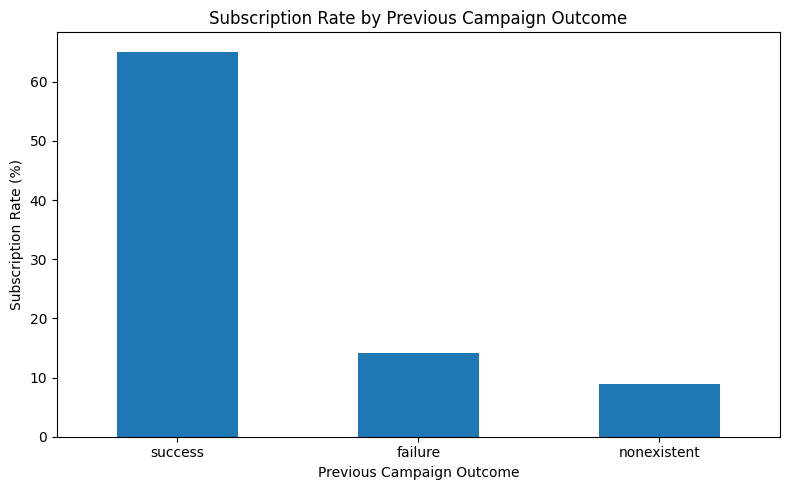

In [40]:
import matplotlib.pyplot as plt

# Calculate subscription rate by previous campaign outcome
poutcome_rate = pd.crosstab(
    df['poutcome'],
    df['y'],
    normalize='index'
) * 100

# Create the bar chart
poutcome_rate['yes'].sort_values(ascending=False).plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Subscription Rate by Previous Campaign Outcome')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [41]:
# Calculate average call duration for each subscription outcome
duration_analysis = df.groupby('y')['duration'].mean()

print(duration_analysis.round(2))

y
no     220.87
yes    553.26
Name: duration, dtype: float64


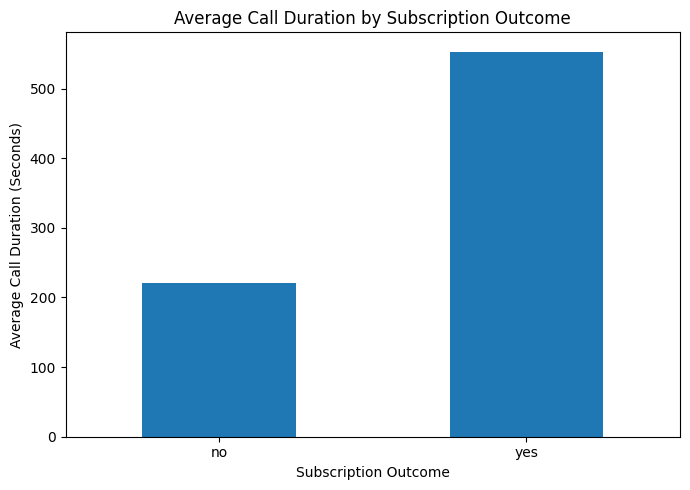

In [42]:
import matplotlib.pyplot as plt

# Calculate average call duration by subscription outcome
duration_analysis = df.groupby('y')['duration'].mean()

# Create the bar chart
duration_analysis.plot(kind='bar', figsize=(7, 5))

plt.title('Average Call Duration by Subscription Outcome')
plt.xlabel('Subscription Outcome')
plt.ylabel('Average Call Duration (Seconds)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [43]:
# Count subscriptions by number of previous contacts
print(pd.crosstab(df['previous'], df['y']))

y            no   yes
previous             
0         32411  3140
1          3594   967
2           404   350
3            88   128
4            32    38
5             5    13
6             2     3
7             1     0


In [44]:
# Calculate subscription rate by number of previous contacts
previous_rate = pd.crosstab(
    df['previous'],
    df['y'],
    normalize='index'
) * 100

print(previous_rate['yes'].round(2))

previous
0     8.83
1    21.20
2    46.42
3    59.26
4    54.29
5    72.22
6    60.00
7     0.00
Name: yes, dtype: float64


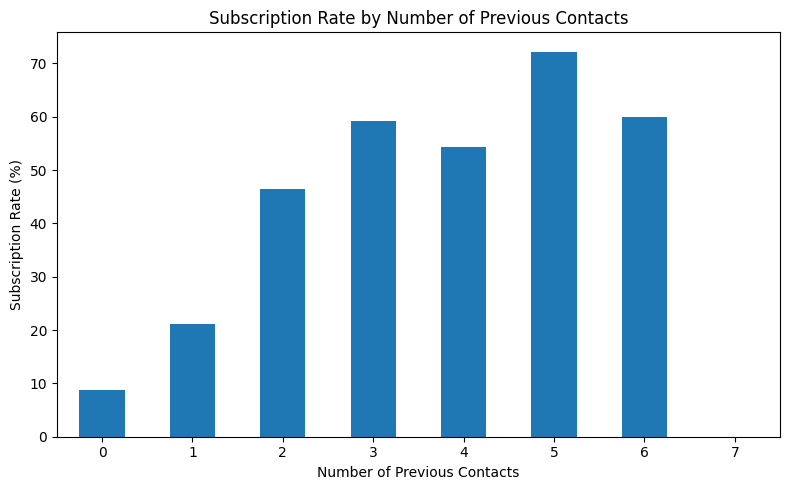

In [45]:
import matplotlib.pyplot as plt

# Calculate subscription rate by previous contacts
previous_rate = pd.crosstab(
    df['previous'],
    df['y'],
    normalize='index'
) * 100

# Create the bar chart
previous_rate['yes'].plot(kind='bar', figsize=(8, 5))

plt.title('Subscription Rate by Number of Previous Contacts')
plt.xlabel('Number of Previous Contacts')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [46]:
# Calculate average call duration for each age group
age_duration = df.groupby('age_group', observed=False)['duration'].mean()

print(age_duration.round(2))

age_group
18-25    271.77
26-35    258.66
36-45    257.14
46-55    253.90
56-65    261.79
66+      280.55
Name: duration, dtype: float64


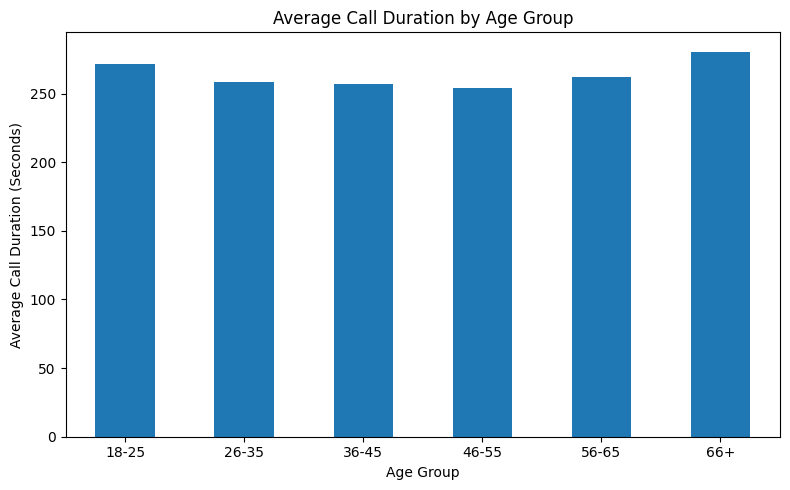

In [47]:
import matplotlib.pyplot as plt

# Calculate average call duration by age group
age_duration = df.groupby(
    'age_group',
    observed=False
)['duration'].mean()

# Create the bar chart
age_duration.plot(kind='bar', figsize=(8, 5))

plt.title('Average Call Duration by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Call Duration (Seconds)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [48]:
# Calculate average campaign contacts by subscription outcome
campaign_analysis = df.groupby('y')['campaign'].mean()

print(campaign_analysis.round(2))

y
no     2.63
yes    2.05
Name: campaign, dtype: float64


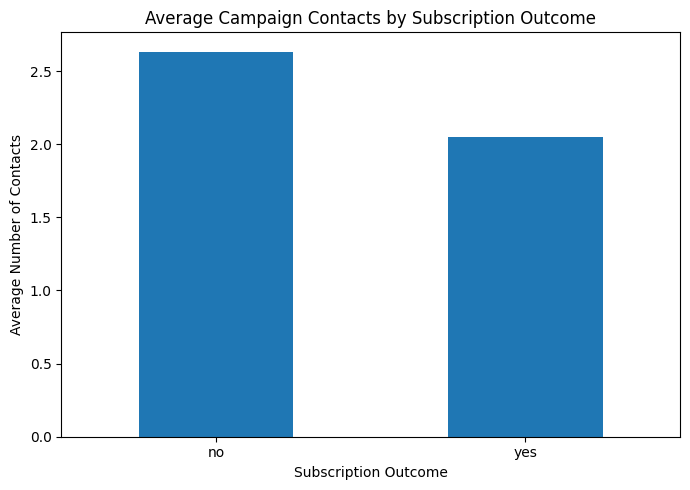

In [49]:
import matplotlib.pyplot as plt

# Calculate average campaign contacts by subscription outcome
campaign_analysis = df.groupby('y')['campaign'].mean()

# Create the bar chart
campaign_analysis.plot(kind='bar', figsize=(7, 5))

plt.title('Average Campaign Contacts by Subscription Outcome')
plt.xlabel('Subscription Outcome')
plt.ylabel('Average Number of Contacts')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [50]:
# Calculate subscription rate by education level
education_rate = pd.crosstab(
    df['education'],
    df['y'],
    normalize='index'
) * 100

# Display subscription rates
print(education_rate['yes'].sort_values(ascending=False).round(2))

education
illiterate             22.22
unknown                14.51
university.degree      13.72
professional.course    11.35
high.school            10.84
basic.4y               10.25
basic.6y                8.21
basic.9y                7.82
Name: yes, dtype: float64


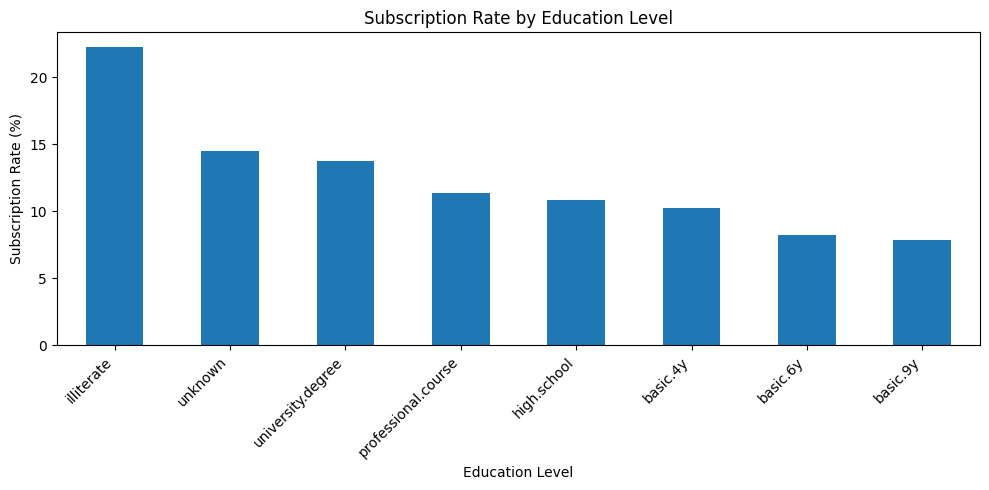

In [51]:
# Calculate subscription rate by education level
education_rate = pd.crosstab(
    df['education'],
    df['y'],
    normalize='index'
) * 100

# Sort from highest to lowest subscription rate
education_rate = education_rate.sort_values(
    by='yes',
    ascending=False
)

# Create the chart
education_rate['yes'].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Subscription Rate by Education Level')
plt.xlabel('Education Level')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [52]:
# Calculate subscription rate by marital status
marital_rate = pd.crosstab(
    df['marital'],
    df['y'],
    normalize='index'
) * 100

# Display subscription rates from highest to lowest
print(marital_rate['yes'].sort_values(ascending=False).round(2))

marital
unknown     15.00
single      14.01
divorced    10.32
married     10.16
Name: yes, dtype: float64


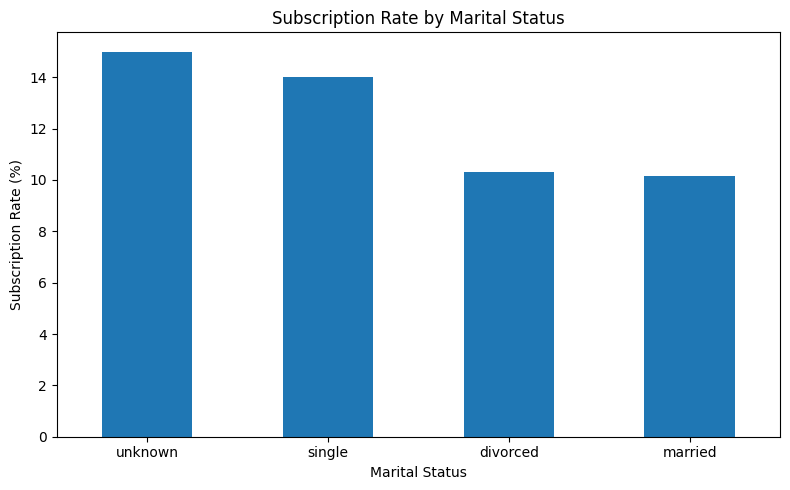

In [53]:
# Calculate subscription rate by marital status
marital_rate = pd.crosstab(
    df['marital'],
    df['y'],
    normalize='index'
) * 100

# Sort from highest to lowest
marital_rate = marital_rate.sort_values(
    by='yes',
    ascending=False
)

# Create the bar chart
marital_rate['yes'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Subscription Rate by Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [54]:
# Count subscription outcomes by number of previous contacts
previous_analysis = pd.crosstab(
    df['previous'],
    df['y']
)

print(previous_analysis)

y            no   yes
previous             
0         32411  3140
1          3594   967
2           404   350
3            88   128
4            32    38
5             5    13
6             2     3
7             1     0


In [55]:
# Calculate subscription rate by number of previous contacts
previous_rate = pd.crosstab(
    df['previous'],
    df['y'],
    normalize='index'
) * 100

print(previous_rate['yes'].round(2))


previous
0     8.83
1    21.20
2    46.42
3    59.26
4    54.29
5    72.22
6    60.00
7     0.00
Name: yes, dtype: float64


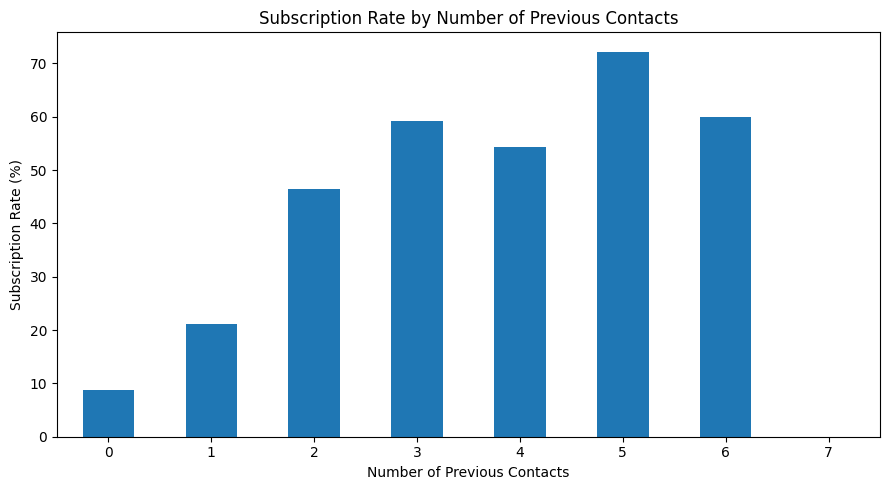

In [56]:
# Calculate subscription rate by number of previous contacts
previous_rate = pd.crosstab(
    df['previous'],
    df['y'],
    normalize='index'
) * 100

# Create the bar chart
previous_rate['yes'].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Subscription Rate by Number of Previous Contacts')
plt.xlabel('Number of Previous Contacts')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [57]:
# Calculate subscription rate by credit default status
default_rate = pd.crosstab(
    df['default'],
    df['y'],
    normalize='index'
) * 100

print(default_rate['yes'].sort_values(ascending=False).round(2))

default
no         12.88
unknown     5.15
yes         0.00
Name: yes, dtype: float64


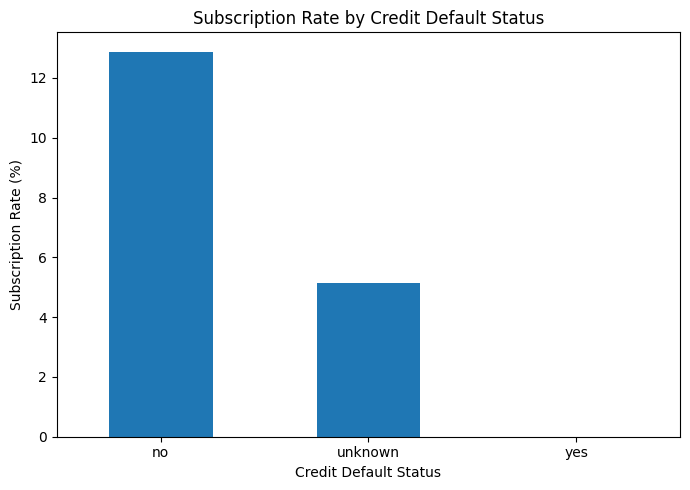

In [58]:
# Calculate subscription rate by credit default status
default_rate = pd.crosstab(
    df['default'],
    df['y'],
    normalize='index'
) * 100

# Sort from highest to lowest subscription rate
default_rate = default_rate.sort_values(
    by='yes',
    ascending=False
)

# Create the bar chart
default_rate['yes'].plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Subscription Rate by Credit Default Status')
plt.xlabel('Credit Default Status')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [59]:
# Calculate subscription rate by housing loan status
housing_rate = pd.crosstab(
    df['housing'],
    df['y'],
    normalize='index'
) * 100

print(housing_rate['yes'].sort_values(ascending=False).round(2))

housing
yes        11.62
no         10.88
unknown    10.81
Name: yes, dtype: float64


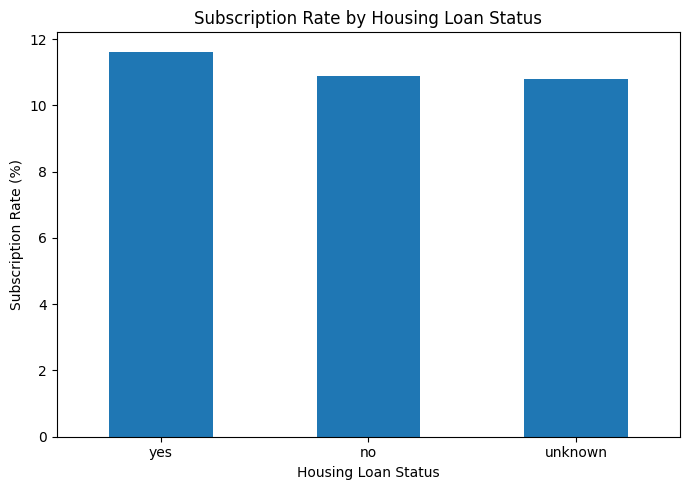

In [60]:
# Calculate subscription rate by housing loan status
housing_rate = pd.crosstab(
    df['housing'],
    df['y'],
    normalize='index'
) * 100

# Sort from highest to lowest subscription rate
housing_rate = housing_rate.sort_values(
    by='yes',
    ascending=False
)

# Create the bar chart
housing_rate['yes'].plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Subscription Rate by Housing Loan Status')
plt.xlabel('Housing Loan Status')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [61]:
# Calculate subscription rate by personal loan status
loan_rate = pd.crosstab(
    df['loan'],
    df['y'],
    normalize='index'
) * 100

print(loan_rate['yes'].sort_values(ascending=False).round(2))

loan
no         11.34
yes        10.93
unknown    10.81
Name: yes, dtype: float64


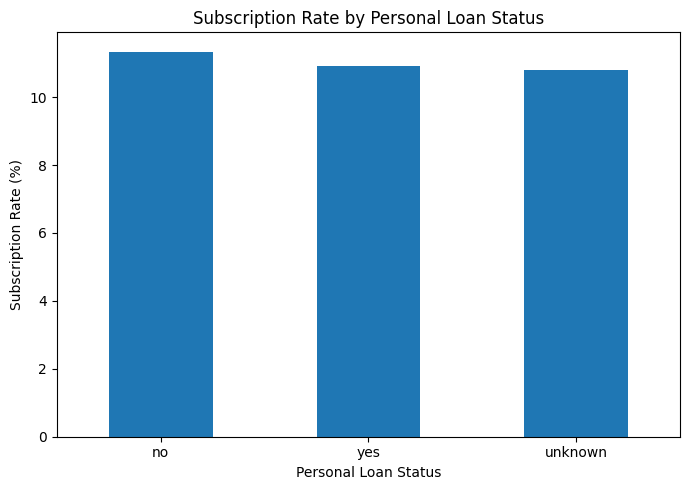

In [62]:
# Calculate subscription rate by personal loan status
loan_rate = pd.crosstab(
    df['loan'],
    df['y'],
    normalize='index'
) * 100

# Sort from highest to lowest subscription rate
loan_rate = loan_rate.sort_values(
    by='yes',
    ascending=False
)

# Create the bar chart
loan_rate['yes'].plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title('Subscription Rate by Personal Loan Status')
plt.xlabel('Personal Loan Status')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

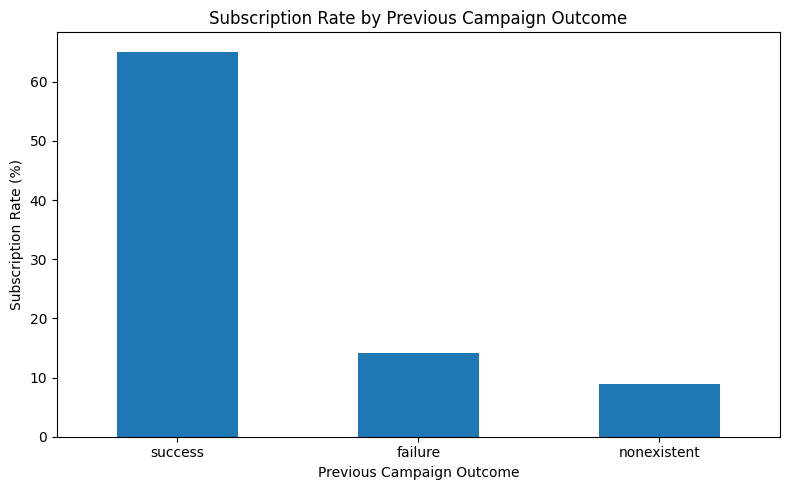

In [63]:
# Calculate subscription rate by previous campaign outcome
poutcome_rate = pd.crosstab(
    df['poutcome'],
    df['y'],
    normalize='index'
) * 100

# Sort from highest to lowest subscription rate
poutcome_rate = poutcome_rate.sort_values(
    by='yes',
    ascending=False
)

# Create the bar chart
poutcome_rate['yes'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Subscription Rate by Previous Campaign Outcome')
plt.xlabel('Previous Campaign Outcome')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [64]:
# Calculate subscription rate by day of the week
day_rate = pd.crosstab(
    df['day_of_week'],
    df['y'],
    normalize='index'
) * 100

# Display subscription rates
print(day_rate['yes'].round(2))

day_of_week
fri    10.81
mon     9.95
thu    12.11
tue    11.79
wed    11.67
Name: yes, dtype: float64


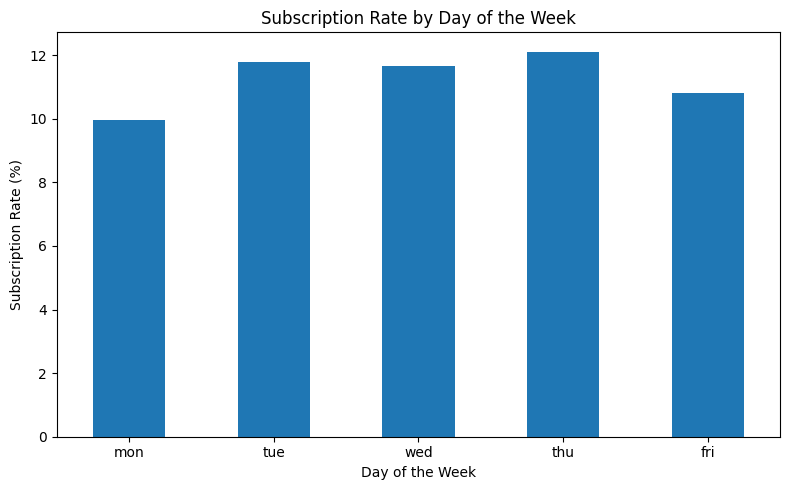

In [65]:
# Calculate subscription rate by day of the week
day_rate = pd.crosstab(
    df['day_of_week'],
    df['y'],
    normalize='index'
) * 100

# Arrange days in weekday order
day_order = ['mon', 'tue', 'wed', 'thu', 'fri']
day_rate = day_rate.reindex(day_order)

# Create the bar chart
day_rate['yes'].plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Subscription Rate by Day of the Week')
plt.xlabel('Day of the Week')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [66]:
# Count subscription outcomes by job category
job_analysis = pd.crosstab(
    df['job'],
    df['y']
)

# Display the results
print(job_analysis.sort_values(by='yes', ascending=False))

y                no   yes
job                      
admin.         9068  1351
technician     6009   730
blue-collar    8615   638
retired        1284   434
management     2596   328
services       3644   323
student         600   275
self-employed  1272   149
unemployed      870   144
entrepreneur   1332   124
housemaid       954   106
unknown         293    37


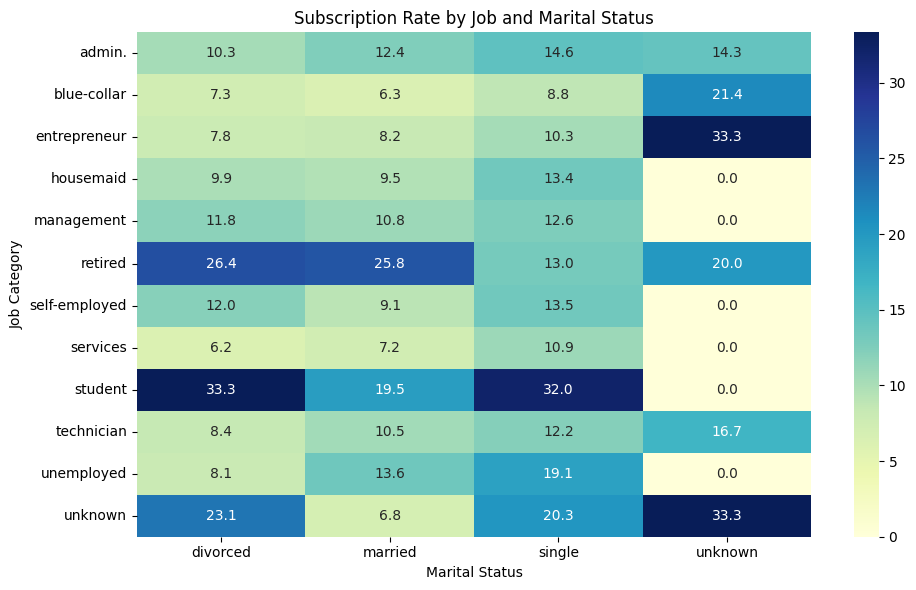

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate subscription rate by job and marital status
job_marital_rate = pd.pivot_table(
    df,
    values='y',
    index='job',
    columns='marital',
    aggfunc=lambda x: (x == 'yes').mean() * 100
)

# Create heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(job_marital_rate, annot=True, fmt='.1f', cmap='YlGnBu')

plt.title('Subscription Rate by Job and Marital Status')
plt.xlabel('Marital Status')
plt.ylabel('Job Category')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2033/2781790754.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  age_contact_rate = pd.pivot_table(


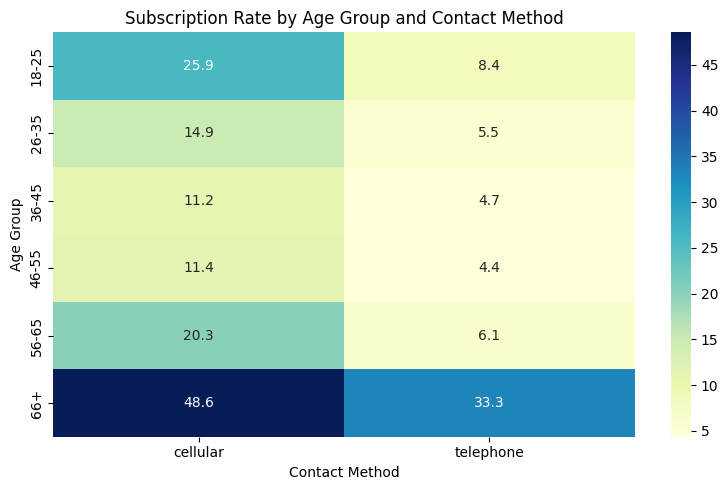

In [68]:
# Calculate subscription rate by age group and contact method
age_contact_rate = pd.pivot_table(
    df,
    values='y',
    index='age_group',
    columns='contact',
    aggfunc=lambda x: (x == 'yes').mean() * 100
)

# Create heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(age_contact_rate, annot=True, fmt='.1f', cmap='YlGnBu')

plt.title('Subscription Rate by Age Group and Contact Method')
plt.xlabel('Contact Method')
plt.ylabel('Age Group')
plt.tight_layout()
plt.show()

In [69]:
# Count customers by subscription outcome
subscription_counts = df['y'].value_counts()

print("Customer Subscription Counts:")
print(subscription_counts)

# Calculate subscription percentages
subscription_percentages = df['y'].value_counts(normalize=True) * 100

print("\nCustomer Subscription Percentages:")
print(subscription_percentages.round(2))

Customer Subscription Counts:
y
no     36537
yes     4639
Name: count, dtype: int64

Customer Subscription Percentages:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


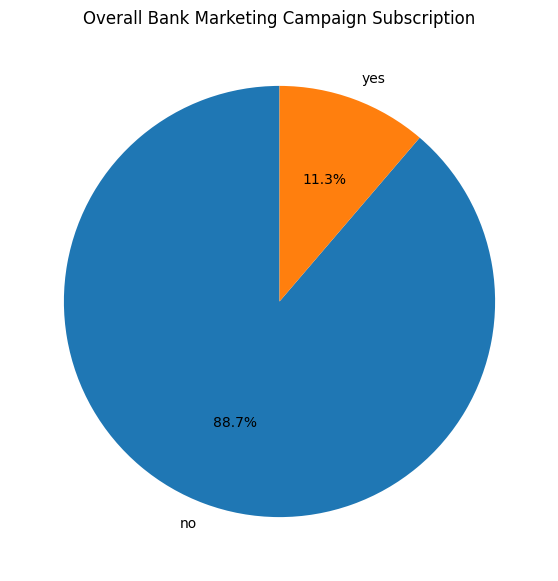

In [70]:
# Calculate subscription counts
subscription_counts = df['y'].value_counts()

# Create a pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    subscription_counts,
    labels=subscription_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Overall Bank Marketing Campaign Subscription')
plt.show()

In [71]:
# Calculate subscription rate by different categories

print("Subscription Rate by Contact Method (%):")
print(
    (pd.crosstab(df['contact'], df['y'], normalize='index') * 100)['yes'].round(2)
)

print("\nSubscription Rate by Job Category (%):")
print(
    (pd.crosstab(df['job'], df['y'], normalize='index') * 100)['yes']
    .sort_values(ascending=False).round(2)
)

print("\nSubscription Rate by Previous Campaign Outcome (%):")
print(
    (pd.crosstab(df['poutcome'], df['y'], normalize='index') * 100)['yes']
    .round(2)
)

print("\nSubscription Rate by Month (%):")
print(
    (pd.crosstab(df['month'], df['y'], normalize='index') * 100)['yes']
    .sort_values(ascending=False).round(2)
)

Subscription Rate by Contact Method (%):
contact
cellular     14.74
telephone     5.23
Name: yes, dtype: float64

Subscription Rate by Job Category (%):
job
student          31.43
retired          25.26
unemployed       14.20
admin.           12.97
management       11.22
unknown          11.21
technician       10.83
self-employed    10.49
housemaid        10.00
entrepreneur      8.52
services          8.14
blue-collar       6.90
Name: yes, dtype: float64

Subscription Rate by Previous Campaign Outcome (%):
poutcome
failure        14.23
nonexistent     8.83
success        65.11
Name: yes, dtype: float64

Subscription Rate by Month (%):
month
mar    50.55
dec    48.90
sep    44.91
oct    43.93
apr    20.49
aug    10.61
jun    10.51
nov    10.15
jul     9.04
may     6.44
Name: yes, dtype: float64


In [72]:
# Count customers in each month
monthly_customers = df['month'].value_counts()

# Calculate subscriptions in each month
monthly_subscriptions = df[df['y'] == 'yes']['month'].value_counts()

# Combine the results
monthly_analysis = pd.DataFrame({
    'Total Customers': monthly_customers,
    'Subscribed Customers': monthly_subscriptions
})

# Calculate subscription rate
monthly_analysis['Subscription Rate (%)'] = (
    monthly_analysis['Subscribed Customers']
    / monthly_analysis['Total Customers'] * 100
)

# Display months in calendar order
month_order = [
    'jan', 'feb', 'mar', 'apr', 'may', 'jun',
    'jul', 'aug', 'sep', 'oct', 'nov', 'dec'
]

monthly_analysis = monthly_analysis.reindex(month_order).dropna(
    subset=['Total Customers']
)

print(monthly_analysis.round(2))

       Total Customers  Subscribed Customers  Subscription Rate (%)
month                                                              
mar              546.0                 276.0                  50.55
apr             2631.0                 539.0                  20.49
may            13767.0                 886.0                   6.44
jun             5318.0                 559.0                  10.51
jul             7169.0                 648.0                   9.04
aug             6176.0                 655.0                  10.61
sep              570.0                 256.0                  44.91
oct              717.0                 315.0                  43.93
nov             4100.0                 416.0                  10.15
dec              182.0                  89.0                  48.90


In [73]:
# Calculate total customers
total_customers = len(df)

# Calculate customers who subscribed
subscribed_customers = (df['y'] == 'yes').sum()

# Calculate conversion rate
conversion_rate = (
    subscribed_customers / total_customers
) * 100

print("Total Customers:", total_customers)
print("Subscribed Customers:", subscribed_customers)
print("Campaign Conversion Rate:", round(conversion_rate, 2), "%")

Total Customers: 41176
Subscribed Customers: 4639
Campaign Conversion Rate: 11.27 %
